# 第 1 章 导论：随机数如何解决问题 — 代码实验

对照教材：Shonkwiler & Mendivil《Explorations in Monte Carlo Methods》第 1 章（§1.1–1.4）。

12 个实验对应正文 12 个知识点，输出图保存为 `out-1-M.png`（M=实验号）供笔记引用。随机种子 2024，全程可复现。

In [1]:
# ===== 公共设置 =====
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

rng = np.random.default_rng(2024)
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei"]
plt.rcParams["axes.unicode_minus"] = False
FIGDIR = Path(r"E:/Desktop/深度学习/mynotes/docs/mc/images/ch01")
FIGDIR.mkdir(parents=True, exist_ok=True)

def save(fig, name):
    fig.savefig(FIGDIR / name, dpi=150, bbox_inches="tight")

print("numpy", np.__version__)

numpy 2.4.6


## 实验 1 蒲丰投针（书 §1.1.1，Alg 1.1）

$d=2,\ L=1$，命中概率 $2L/(\pi d)=1/\pi$。估计量 $\hat\pi=n/H_n$（注意：渐近有效但有偏，见笔记"坑与陷阱"1）。看两件事：(a) $\hat\pi$ 随 $n$ 的收敛；(b) 分批估计的误差是否按 $1/\sqrt{n}$ 衰减。

n=10,000:  π̂ = 3.1260   (书用同样参数跑出 ≈3.15 量级)


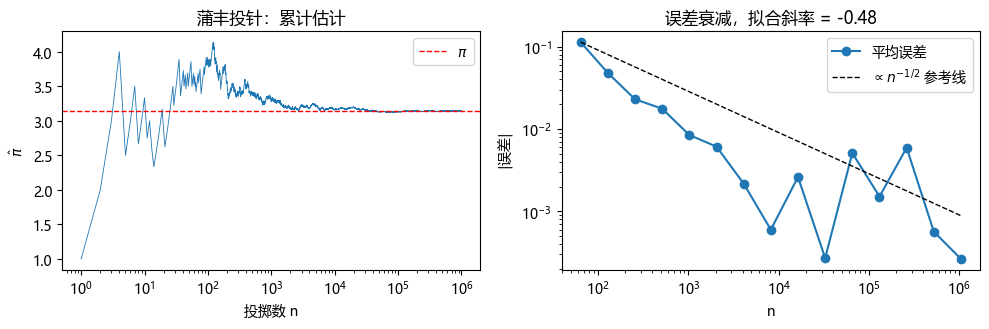

结论：精度只按 1/√n 改善——十倍样本换约 3.2 倍精度。


In [2]:
# ===== 书 §1.1.1 蒲丰投针 =====
d, L = 2.0, 1.0

def buffon(n, r=rng):
    x = r.uniform(0, d/2, n)              # X ~ U(0, d/2)
    theta = r.uniform(0, np.pi/2, n)      # Θ ~ U(0, π/2)
    hits = np.sum(x <= 0.5*np.sin(theta))
    return n / hits                        # π̂ = n/Hn（书 Alg 1.1）

est1 = buffon(10_000)
print(f"n=10,000:  π̂ = {est1:.4f}   (书用同样参数跑出 ≈3.15 量级)")

# (a) 收敛轨迹：累计估计
N = 1_000_000
x = rng.uniform(0, d/2, N); th = rng.uniform(0, np.pi/2, N)
hit = (x <= 0.5*np.sin(th)).astype(float)
cum_hits = np.cumsum(hit)
ns = np.arange(1, N+1)
pi_hat = ns / np.maximum(cum_hits, 1)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].plot(ns, pi_hat, lw=0.6)
ax[0].axhline(np.pi, color="r", ls="--", lw=1, label=r"$\pi$")
ax[0].set_xscale("log"); ax[0].set_xlabel("投掷数 n"); ax[0].set_ylabel(r"$\hat\pi$")
ax[0].set_title("蒲丰投针：累计估计"); ax[0].legend()

# (b) 误差 vs n：独立分批，每批 n 次投掷取一个估计，取 |均值-π|
sizes = [2**k for k in range(6, 21)]
errs = []
for n in sizes:
    reps = max(1, 2_000_000 // n)
    vals = np.array([buffon(n) for _ in range(reps)])
    errs.append(abs(vals.mean() - np.pi))
ax[1].loglog(sizes, errs, "o-", label="平均误差")
ref = errs[0] * (np.array(sizes)/sizes[0])**(-0.5)
ax[1].loglog(sizes, ref, "k--", lw=1, label=r"$\propto n^{-1/2}$ 参考线")
slope = np.polyfit(np.log(sizes), np.log(errs), 1)[0]
ax[1].set_title(f"误差衰减，拟合斜率 = {slope:.2f}")
ax[1].set_xlabel("n"); ax[1].set_ylabel(r"$|$误差$|$"); ax[1].legend()
plt.tight_layout(); save(fig, "out-1-1.png"); plt.show()
print("结论：精度只按 1/√n 改善——十倍样本换约 3.2 倍精度。")

## 实验 2 直方图 super-experiment（书 §1.1.2，Alg 1.3）

100 次投掷估 $1/\pi$，重复 2000 次做密度直方图：钟形（正态）、均值 ≈ 0.318、标准差 ≈ 0.047（书：$\bar p=0.3180,\ s=0.0467$）。再按 $2\sigma/\sqrt{2000}$ 挂出 95.4% 区间并取倒数得 $\pi$ 区间。

1/π 估计: 0.3195  (真值 0.3183)   s = 0.0470
95.4% 区间: [0.3174, 0.3216]  →  π ∈ [3.110, 3.151]


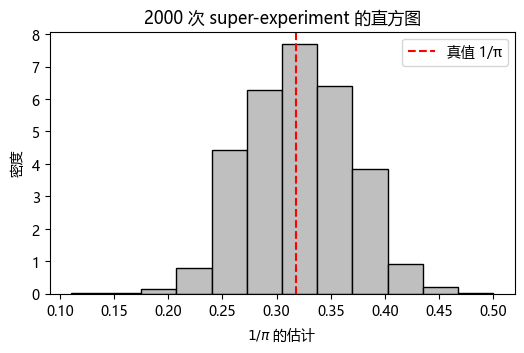

In [3]:
# ===== 书 §1.1.2 Alg 1.3 =====
throws, replications = 100, 2000
y = np.empty(replications)
for i in range(replications):
    x = rng.uniform(0, d/2, throws)
    theta = rng.uniform(0, np.pi/2, throws)
    y[i] = np.sum(x <= 0.5*np.sin(theta)) / throws

recip_est = y.mean()                       # ≈ 1/π
v = np.sum((y - recip_est)**2) / (replications - 1)   # 样本方差（书式）
stddev = np.sqrt(v)
half = 2 * stddev / np.sqrt(replications)
print(f"1/π 估计: {recip_est:.4f}  (真值 {1/np.pi:.4f})   s = {stddev:.4f}")
print(f"95.4% 区间: [{recip_est-half:.4f}, {recip_est+half:.4f}]"
      f"  →  π ∈ [{1/(recip_est+half):.3f}, {1/(recip_est-half):.3f}]")

fig, ax = plt.subplots(figsize=(6, 3.4))
ax.hist(y, bins=12, density=True, color="0.75", edgecolor="k")
ax.axvline(1/np.pi, color="r", ls="--", label="真值 1/π")
ax.set_xlabel(r"$1/\pi$ 的估计"); ax.set_ylabel("密度")
ax.set_title("2000 次 super-experiment 的直方图")
ax.legend(); save(fig, "out-1-2.png"); plt.show()

## 实验 3 赌徒的财富：样本路径 + 破产时长（书 §1.1.3，Alg 1.4）

$100 对 $2100，每局 ±$1、胜率 50%。注意破产时长 $T$ **无上界**且重尾（第 4 章将证明均值 $T(x)=x(a-x)=2\times10^5$ 局）。

单局样本路径长度 = 840320 步，终态 = 0（0=输光, 2100=胜）


20 次破产时长: 均值 = 144,932（理论 x(a-x) = 200,000），最大 = 1,278,908


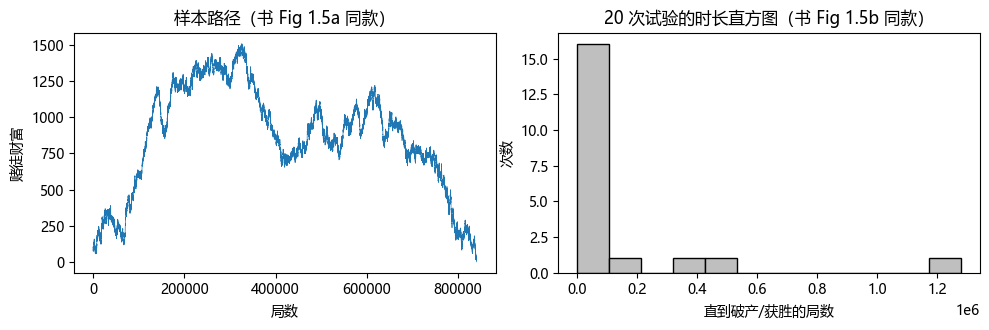

In [4]:
# ===== 书 §1.1.3 Alg 1.4 =====
a = 2100; start = 100; MAXSTEPS = 3_000_000   # 保护性上限，仅防意外死循环

def one_run(r=rng):
    R = [start]
    while 0 < R[-1] < a and len(R) < MAXSTEPS:
        R.append(R[-1] + (1 if r.random() < 0.5 else -1))
    return R

R = one_run()
print(f"单局样本路径长度 = {len(R)-1} 步，终态 = {R[-1]}（0=输光, {a}=胜）")

T = []
for _ in range(20):
    T.append(len(one_run()) - 1)
T = np.array(T)
print(f"20 次破产时长: 均值 = {T.mean():,.0f}（理论 x(a-x) = {start*(a-start):,}），"
      f"最大 = {T.max():,}")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].plot(R, lw=0.5)
ax[0].set_xlabel("局数"); ax[0].set_ylabel("赌徒财富")
ax[0].set_title("样本路径（书 Fig 1.5a 同款）")
ax[1].hist(T, bins=12, color="0.75", edgecolor="k")
ax[1].set_xlabel("直到破产/获胜的局数"); ax[1].set_ylabel("次数")
ax[1].set_title("20 次试验的时长直方图（书 Fig 1.5b 同款）")
plt.tight_layout(); save(fig, "out-1-3.png"); plt.show()

## 实验 4 双骰子直方图：样本量的作用（书 §1.1.2，Fig 1.4）

1000 次 vs 10000 次。理论概率 $\Pr(S=s)=\{1,2,3,4,5,6,5,4,3,2,1\}/36$。

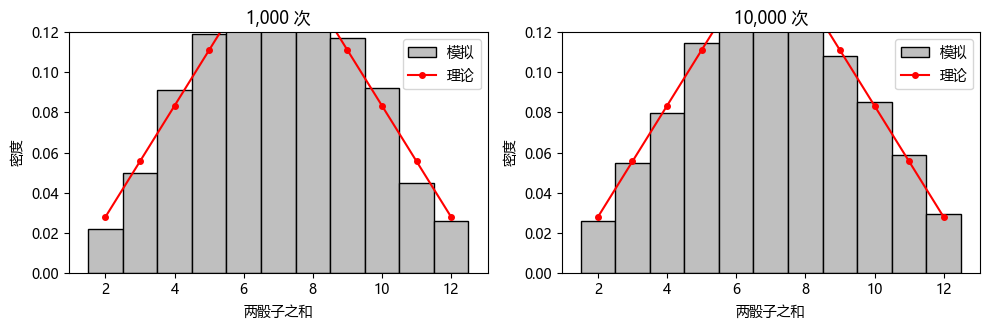

In [5]:
# ===== 书 §1.1.2 双骰子 =====
theory = np.array([1,2,3,4,5,6,5,4,3,2,1]) / 36

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
for k, n in enumerate([1000, 10_000]):
    s = rng.integers(1, 7, n) + rng.integers(1, 7, n)
    ax[k].hist(s, bins=np.arange(1.5, 13.5), density=True,
               color="0.75", edgecolor="k", label="模拟")
    ax[k].plot(np.arange(2, 13), theory, "ro-", ms=4, label="理论")
    ax[k].set_title(f"{n:,} 次"); ax[k].set_xlabel("两骰子之和"); ax[k].set_ylabel("密度")
    ax[k].set_ylim(0, 0.12); ax[k].legend()
plt.tight_layout(); save(fig, "out-1-4.png"); plt.show()

## 实验 5 经验 cdf（书 §1.2.2，Fig 1.6 / 1.7）

离散随机变量的 cdf 是阶梯函数，跳高 = 该点概率；连续极限下 0 与 1。

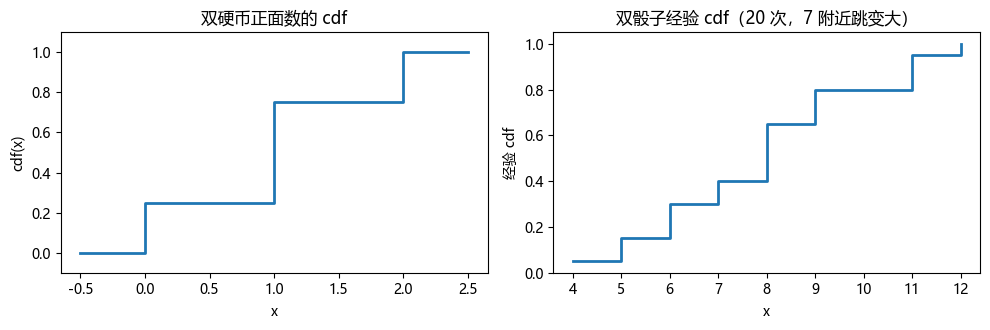

In [6]:
# ===== 书 §1.2.2 cdf =====
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
# (a) 双硬币正面数的精确 cdf（书 Fig 1.6）
px = np.array([1/4, 1/2, 1/4])
cdf = np.concatenate([[0], np.cumsum(px)])
ax[0].step([-0.5,0,0,1,1,2,2,2.5], [0,0,.25,.25,.75,.75,1,1], where="post", lw=2)
ax[0].set_title("双硬币正面数的 cdf"); ax[0].set_xlabel("x"); ax[0].set_ylabel("cdf(x)")
ax[0].set_ylim(-0.1, 1.1)
# (b) 20 次双骰子的经验 cdf（书 Fig 1.7）
nRolls = 20
dice = rng.integers(1, 7, nRolls) + rng.integers(1, 7, nRolls)
xs = np.sort(dice)
ax[1].step(xs, np.arange(1, nRolls+1)/nRolls, where="post", lw=2)
ax[1].set_title(f"双骰子经验 cdf（{nRolls} 次，7 附近跳变大）")
ax[1].set_xlabel("x"); ax[1].set_ylabel("经验 cdf"); ax[1].set_ylim(0, 1.05)
plt.tight_layout(); save(fig, "out-1-5.png"); plt.show()

## 实验 6 大数定律与 $1/\sqrt{n}$（书 §1.2.4，式 (1.25)）

单骰子 $\mu=3.5$，$\operatorname{var}=35/12$。样本均值的 2σ 带宽 $=2\sigma/\sqrt{n}$。

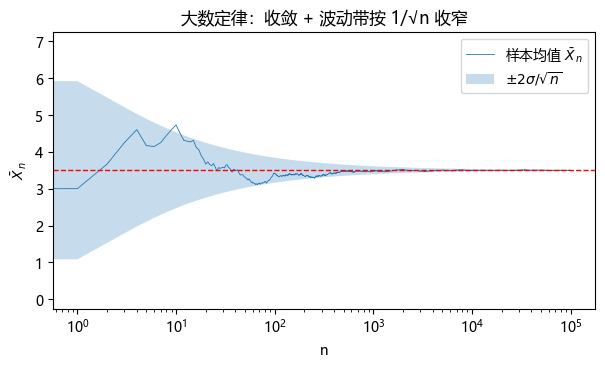

In [7]:
# ===== 书 §1.2.4 LLN =====
N = 100_000
X = rng.integers(1, 7, N)
run = np.cumsum(X) / np.arange(1, N+1)
sig2 = 35/12
band = 2*np.sqrt(sig2/np.arange(1, N+1))

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(run, lw=0.6, label=r"样本均值 $\bar X_n$")
ax.fill_between(np.arange(N), 3.5-band, 3.5+band, alpha=0.25, label=r"$\pm2\sigma/\sqrt{n}$")
ax.axhline(3.5, color="r", ls="--", lw=1)
ax.set_xscale("log"); ax.set_xlabel("n"); ax.set_ylabel(r"$\bar X_n$")
ax.set_title("大数定律：收敛 + 波动带按 1/√n 收窄")
ax.legend(); save(fig, "out-1-6.png"); plt.show()

## 实验 7 切比雪夫不等式实测（书 §1.2.4，式 (1.26)）

$\Pr(|X-\mu|\ge k\sigma)\le 1/k^2$ 对**一切**有限方差分布成立，但松紧差很多：均匀分布远紧于界，重尾的 $t_3$ 分布贴近界。

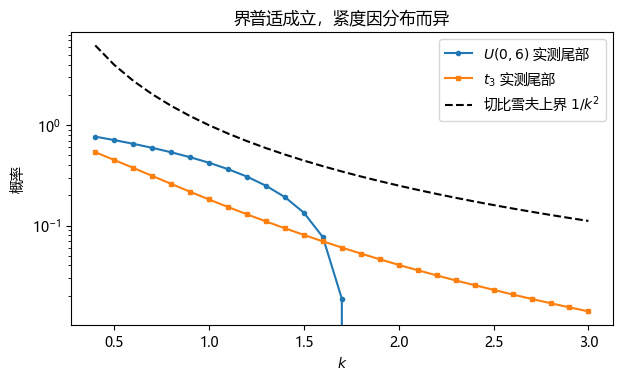

In [8]:
# ===== 书 §1.2.4 Chebyshev =====
from scipy import stats
ks = np.linspace(0.4, 3, 27)
Xu = rng.uniform(0, 6, 2_000_000); mu, sg = 3.0, np.sqrt(3.0)
tail_u = [np.mean(np.abs(Xu-mu) >= k*sg) for k in ks]
Xt = stats.t.rvs(3, size=2_000_000, random_state=2024)   # t3: var=3, μ=0
tail_t = [np.mean(np.abs(Xt) >= k*np.sqrt(3)) for k in ks]

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(ks, tail_u, "o-", ms=3, label=r"$U(0,6)$ 实测尾部")
ax.plot(ks, tail_t, "s-", ms=3, label=r"$t_3$ 实测尾部")
ax.plot(ks, 1/ks**2, "k--", lw=1.5, label=r"切比雪夫上界 $1/k^2$")
ax.set_yscale("log"); ax.set_xlabel(r"$k$"); ax.set_ylabel("概率")
ax.set_title("界普适成立，紧度因分布而异"); ax.legend()
save(fig, "out-1-7.png"); plt.show()

## 实验 8 贝叶斯公式：出租车 + 蒙提霍尔（书 §1.2.6）

出租车：精确值 0.4138。蒙提霍尔：换门 2/3、不换 1/3。

出租车 Pr(蓝|称蓝): 精确 = 0.4138，模拟 = 0.4153
蒙提霍尔: 不换胜率 = 0.3317（1/3），换门胜率 = 0.6683（2/3）


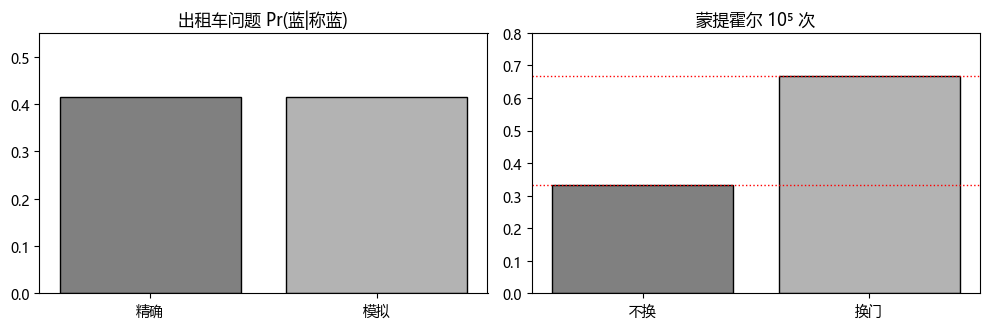

In [9]:
# ===== 书 §1.2.6 Bayes =====
# (a) 出租车问题（Kahneman–Tversky）
pB, witness = 0.15, 0.80
exact = witness*pB / (witness*pB + (1-witness)*(1-pB))
N = 1_000_000
blue = rng.random(N) < pB
correct = rng.random(N) < witness
said_blue = correct == blue          # 说"蓝"：蓝车说对 或 绿车说错
sim = np.mean(blue & said_blue) / np.mean(said_blue)
print(f"出租车 Pr(蓝|称蓝): 精确 = {exact:.4f}，模拟 = {sim:.4f}")

# (b) 蒙提霍尔（标准版：主持人总开羊门）
N = 100_000
car = rng.integers(0, 3, N)
pick = rng.integers(0, 3, N)
win_stay = np.mean(car == pick)
# 换门获胜 = 车不在所选门（主持人总能开掉一只羊）
win_switch = np.mean(car != pick)
print(f"蒙提霍尔: 不换胜率 = {win_stay:.4f}（1/3），换门胜率 = {win_switch:.4f}（2/3）")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].bar(["精确", "模拟"], [exact, sim], color=["0.5", "0.7"], edgecolor="k")
ax[0].set_ylim(0, 0.55); ax[0].set_title("出租车问题 Pr(蓝|称蓝)")
ax[1].bar(["不换", "换门"], [win_stay, win_switch], color=["0.5", "0.7"], edgecolor="k")
ax[1].axhline(1/3, color="r", ls=":", lw=1); ax[1].axhline(2/3, color="r", ls=":", lw=1)
ax[1].set_ylim(0, 0.8); ax[1].set_title("蒙提霍尔 10⁵ 次")
plt.tight_layout(); save(fig, "out-1-8.png"); plt.show()

## 实验 9 LCRNG：小模数序列 + 网格结构（书 §1.3.3）

(a) $a=5,c=1,m=8$、种子 0 的序列应与书一致；(b) $m=2^{11}$ 的 LCRNG 在 $（x_n,x_{n+1}）$ 散点图上露出**格线结构**——"看似随机"背后的确定骨架；(c) NumPy 的 uniform 作对照。

m=8 序列: [0, 1, 6, 7, 4, 5, 2, 3, 0] （书：0,1,6,7,4,5,2,3,0）


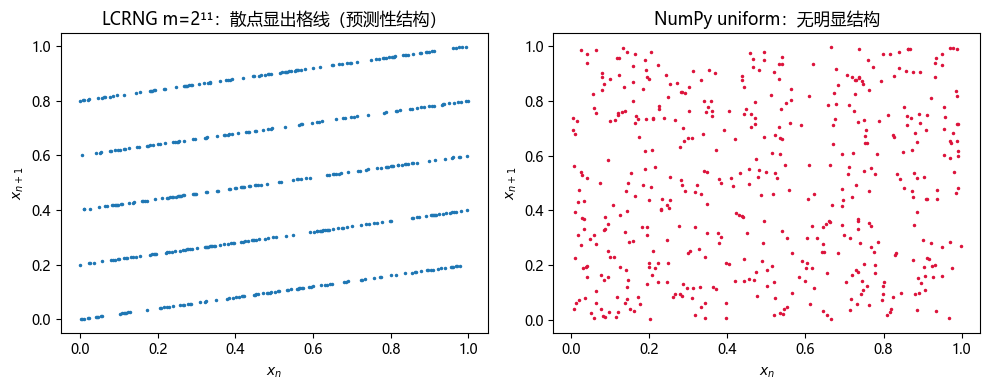

In [10]:
# ===== 书 §1.3.3 LCRNG =====
# (a) 书例：0,1,6,7,4,5,2,3,0
a8, c8, m8, x = 5, 1, 8, 0
seq = []
for _ in range(9):
    seq.append(x); x = (a8*x + c8) % m8
print("m=8 序列:", seq, "（书：0,1,6,7,4,5,2,3,0）")

# (b) 网格结构：m=2^11, a=1229, c=1
m, a, c, x = 2**11, 1229, 1, 1
xs = np.empty(500)
for i in range(500):
    x = (a*x + c) % m
    xs[i] = x / m
# (c) numpy uniform 对照
ys = rng.uniform(size=500)

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].plot(xs[:-1], xs[1:], ".", ms=3)
ax[0].set_title("LCRNG m=2¹¹：散点显出格线（预测性结构）")
ax[0].set_xlabel(r"$x_n$"); ax[0].set_ylabel(r"$x_{n+1}$")
ax[1].plot(ys[:-1], ys[1:], ".", ms=3, color="crimson")
ax[1].set_title("NumPy uniform：无明显结构")
ax[1].set_xlabel(r"$x_n$"); ax[1].set_ylabel(r"$x_{n+1}$")
plt.tight_layout(); save(fig, "out-1-9.png"); plt.show()

## 实验 10 hit-or-miss 估 π（书 §1.4，Alg 1.9）

单位方形内撒点，落在四分之一单位圆内即命中：$\pi\approx 4h/n$。验证误差按 $1/\sqrt{n}$ 衰减（书 Fig 1.13）。

n=10,000:  π̂ = 3.1644（书 ≈3.1316）


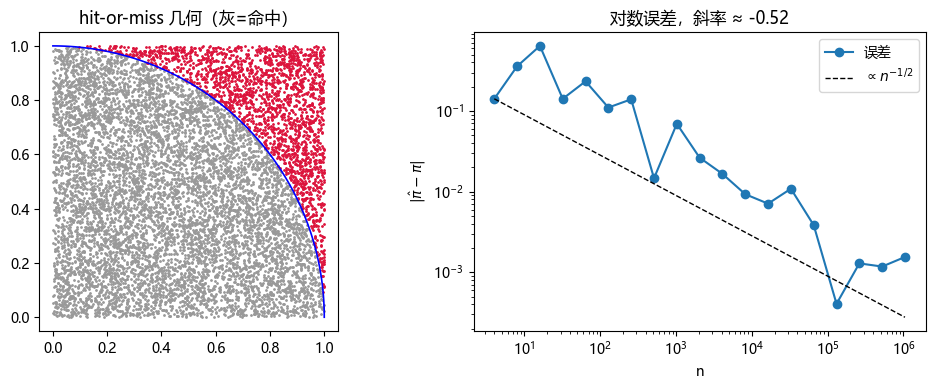

In [11]:
# ===== 书 §1.4 Alg 1.9 =====
N0 = 10_000
x0, y0 = rng.uniform(size=N0), rng.uniform(size=N0)
inside = x0**2 + y0**2 < 1
pi_est = 4*np.sum(inside)/N0
print(f"n=10,000:  π̂ = {pi_est:.4f}（书 ≈3.1316）")

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].scatter(x0[inside], y0[inside], s=1, color="0.6")
ax[0].scatter(x0[~inside], y0[~inside], s=1, color="crimson")
th = np.linspace(0, np.pi/2, 100)
ax[0].plot(np.cos(th), np.sin(th), "b-", lw=1.2)
ax[0].set_aspect("equal"); ax[0].set_title("hit-or-miss 几何（灰=命中）")
sizes = [2**k for k in range(2, 21)]
errs = [abs(4*np.mean(rng.uniform(size=n)**2 + rng.uniform(size=n)**2 < 1) - np.pi)
        for n in sizes]
ax[1].loglog(sizes, errs, "o-", label="误差")
slope = np.polyfit(np.log(sizes), np.log(errs), 1)[0]
ref = errs[0]*(np.array(sizes)/sizes[0])**(-0.5)
ax[1].loglog(sizes, ref, "k--", lw=1, label=r"$\propto n^{-1/2}$")
ax[1].set_title(f"对数误差，斜率 ≈ {slope:.2f}")
ax[1].set_xlabel("n"); ax[1].set_ylabel(r"$|\hat\pi-\pi|$"); ax[1].legend()
plt.tight_layout(); save(fig, "out-1-10.png"); plt.show()

## 实验 11 优惠券收集：ANGELFISH（书 §1.4，Alg 1.10）

9 个字母等可能，集齐为止。理论期望 $nH_n=9\times(1+1/2+\cdots+1/9)\approx 25.46$。

模拟均值 = 25.51，解析 nH_n = 25.46


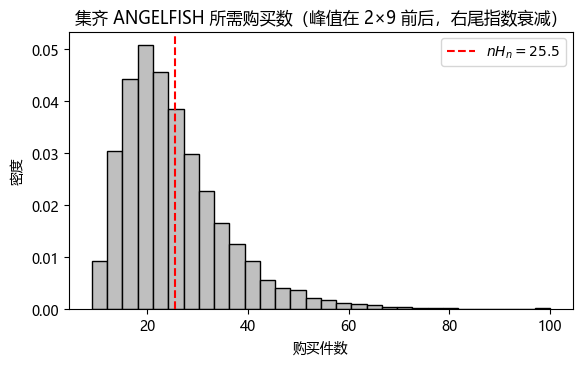

In [12]:
# ===== 书 §1.4 Alg 1.10 =====
nLetters, nTrials = 9, 10_000
nTries = np.zeros(nTrials, dtype=int)
for i in range(nTrials):
    got = np.zeros(nLetters, dtype=bool)
    while not got.all():
        nTries[i] += 1
        got[rng.integers(0, nLetters)] = True

H = np.sum(1/np.arange(1, nLetters+1))
print(f"模拟均值 = {nTries.mean():.2f}，解析 nH_n = {nLetters*H:.2f}")

fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.hist(nTries, bins=30, color="0.75", edgecolor="k", density=True)
ax.axvline(nLetters*H, color="r", ls="--", label=f"$nH_n={nLetters*H:.1f}$")
ax.set_xlabel("购买件数"); ax.set_ylabel("密度")
ax.set_title("集齐 ANGELFISH 所需购买数（峰值在 2×9 前后，右尾指数衰减）")
ax.legend(); save(fig, "out-1-11.png"); plt.show()

## 实验 12 Fisher–Yates 洗牌的均匀性（书 §1.4，Alg 1.11）

洗 9 张牌 10 万次：每张牌出现在每个位置的频次应均匀（$100000/9\approx 1.1\times10^4$），用卡方统计量验收。

每位置 χ²（DOF=8，95% 接受限 15.51）: min=1.4, max=11.7


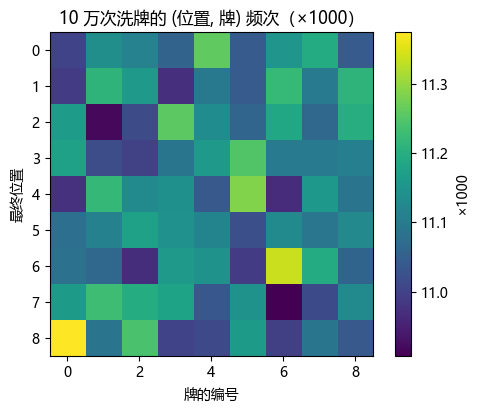

In [13]:
# ===== 书 §1.4 Alg 1.11 =====
n, nShuffles = 9, 100_000
counts = np.zeros((n, n), dtype=int)      # counts[位置, 牌]
for _ in range(nShuffles):
    perm = list(range(n))
    for i in range(n):                    # 全量洗牌 m = n
        j = rng.integers(i, n)            # 从剩余位置等可能选（半开区间版）
        perm[i], perm[j] = perm[j], perm[i]
    for i, p in enumerate(perm):
        counts[i, p] += 1

expected = nShuffles / n
chi2 = ((counts - expected)**2 / expected).sum(axis=1)   # 每个位置的 χ²，DOF=8
print(f"每位置 χ²（DOF=8，95% 接受限 15.51）: min={chi2.min():.1f}, max={chi2.max():.1f}")

fig, ax = plt.subplots(figsize=(5.6, 4.2))
im = ax.imshow(counts/1000, cmap="viridis")
ax.set_xlabel("牌的编号"); ax.set_ylabel("最终位置")
ax.set_title("10 万次洗牌的 (位置, 牌) 频次（×1000）")
fig.colorbar(im, ax=ax, label="×1000")
save(fig, "out-1-12.png"); plt.show()